# Conformal ranks and geographic failure
        A finite-sample rank gives a precise marginal statement under exchangeability.
        A shifted test population need not satisfy it. [Chapter](../docs/03_uncertainty_and_shift.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
from learning_lab.uncertainty import conformal_quantile, regression_interval
scores = np.arange(9, dtype=float)
q = conformal_quantile(scores, alpha=.2)
assert q == 7  # ceil((9+1)*.8) is the eighth order statistic
assert np.isinf(conformal_quantile(np.array([.1, .2]), alpha=.1))
print('Correct finite-sample cutoff:', q)

Correct finite-sample cutoff: 7.0


## Repeated exchangeable draws versus one shifted population
        The following simulation reuses no fitting labels. Calibration residuals have
        zero mean; the shifted observations have a systematic mean error.

In [3]:
rng = np.random.default_rng(4)
cal = rng.normal(size=500)
test = rng.normal(size=5000)
shifted = test + 2
lower, upper = regression_interval(np.zeros(len(test)), np.zeros(len(cal)), cal)
print('Exchangeable empirical coverage:', np.mean((test>=lower)&(test<=upper)))
print('Shifted empirical coverage:', np.mean((shifted>=lower)&(shifted<=upper)))

Exchangeable empirical coverage: 0.9002
Shifted empirical coverage: 0.3564


## Inspect the real housing study
        The geographic holdout uses longitude, not target labels. Both protocols refit
        models; this changes the fitting population as well as the evaluation population.

In [4]:
rows = pd.DataFrame(evidence('regression')['rows'])
rows['coverage'] = rows.split_conformal.map(lambda z: z['coverage'])
rows['width'] = rows.split_conformal.map(lambda z: z['mean_width'])
rows.groupby(['protocol','model'])[['rmse','coverage','width']].mean()

rmse  coverage     width
protocol   model                                            
geographic bayesian_ridge       0.658223  0.937450  2.194829
           feature_transformer  0.806526  0.727940  1.628232
           hist_boosting        0.873842  0.513005  1.372458
           ridge                0.659662  0.937291  2.191962
random     bayesian_ridge       0.730542  0.898417  2.137503
           feature_transformer  0.520880  0.900355  1.578602
           hist_boosting        0.463012  0.898256  1.372903
           ridge                0.731315  0.897933  2.134966

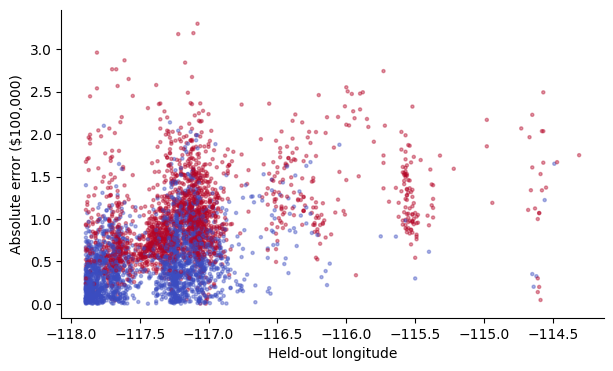

Observed CQR coverage in the shifted region: 0.5122067975107707


In [5]:
intervals = np.load(root/'assets/source_data/regression_intervals_geographic_0.npz')
error = abs(intervals['y']-intervals['pred'])
covered = (intervals['y']>=intervals['lower']) & (intervals['y']<=intervals['upper'])
plt.scatter(intervals['longitude'], error, c=covered, cmap='coolwarm_r', s=5, alpha=.4)
plt.xlabel('Held-out longitude'); plt.ylabel('Absolute error ($100,000)'); plt.show()
print('Observed CQR coverage in the shifted region:', covered.mean())

## Exercise and worked answer
        Does a prediction interval that includes 90% of calibration labels necessarily
        include 90% of the shifted test labels? No. The rank argument requires compatible
        calibration and test draws. The measured geographic coverage is a stress result,
        not a shifted-data theorem. Interval width and capped-target behavior also matter.